In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.weightstats import ztest
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

#Splitting data
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("Data loaded successfully! ")

print(train_df)
print(test_df)

Data loaded successfully! 
        Unnamed: 0      id  Gender      Customer Type  Age   Type of Travel  \
0                0   70172    Male     Loyal Customer   13  Personal Travel   
1                1    5047    Male  disloyal Customer   25  Business travel   
2                2  110028  Female     Loyal Customer   26  Business travel   
3                3   24026  Female     Loyal Customer   25  Business travel   
4                4  119299    Male     Loyal Customer   61  Business travel   
...            ...     ...     ...                ...  ...              ...   
103899      103899   94171  Female  disloyal Customer   23  Business travel   
103900      103900   73097    Male     Loyal Customer   49  Business travel   
103901      103901   68825    Male  disloyal Customer   30  Business travel   
103902      103902   54173  Female  disloyal Customer   22  Business travel   
103903      103903   62567    Male     Loyal Customer   27  Business travel   

           Class  Flight

In [10]:
#Data Cleaning

#Deleting Useless ID Columns
train_df = train_df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')
test_df = test_df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')

# Fill missing Arrival Delays with the median  value
train_df['Arrival Delay in Minutes'] = train_df['Arrival Delay in Minutes'].fillna(train_df['Arrival Delay in Minutes'].median())
test_df['Arrival Delay in Minutes'] = test_df['Arrival Delay in Minutes'].fillna(test_df['Arrival Delay in Minutes'].median())

# 3. Convert text to numbers
safe_mapping = {
    'neutral or dissatisfied': 0, 'satisfied': 1,
    'Male': 0, 'Female': 1,
    'disloyal Customer': 0, 'Loyal Customer': 1,
    'Personal Travel': 0, 'Business travel': 1,
    'Eco': 0, 'Eco Plus': 1, 'Business': 2
}

train_df = train_df.replace(safe_mapping)
test_df = test_df.replace(safe_mapping)

train_df = train_df.fillna(0)
test_df = test_df.fillna(0)

print("Data Cleaned Successfully!")
display(train_df.head(10))


Data Cleaned Successfully!


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,1,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,0
1,0,0,25,1,2,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,0
2,1,1,26,1,2,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,1
3,1,1,25,1,2,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,0
4,0,1,61,1,2,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,1
5,1,1,26,0,0,1180,3,4,2,1,...,1,3,4,4,4,4,1,0,0.0,0
6,0,1,47,0,0,1276,2,4,2,3,...,2,3,3,4,3,5,2,9,23.0,0
7,1,1,52,1,2,2035,4,3,4,4,...,5,5,5,5,4,5,4,4,0.0,1
8,1,1,41,1,2,853,1,2,2,2,...,1,1,2,1,4,1,2,0,0.0,0
9,0,0,20,1,0,1061,3,3,3,4,...,2,2,3,4,4,3,2,0,0.0,0


In [11]:
#Central Tendency
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes']

print("\nMEAN:")
print(train_df[num_cols].mean().round(2))

print("\nMEDIAN:")
print(train_df[num_cols].median())

print("\nMODE:")
print(train_df[num_cols].mode().iloc[0])


MEAN:
Age                             39.38
Flight Distance               1189.45
Departure Delay in Minutes      14.82
dtype: float64

MEDIAN:
Age                            40.0
Flight Distance               843.0
Departure Delay in Minutes      0.0
dtype: float64

MODE:
Age                            39
Flight Distance               337
Departure Delay in Minutes      0
Name: 0, dtype: int64


C:\Users\Anshuman\AppData\Local\Temp\ipykernel_30008\1659907573.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Flight Distance', data=train_df, ax=axes[0, 1], palette='Set2')
C:\Users\Anshuman\AppData\Local\Temp\ipykernel_30008\1659907573.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='satisfaction', data=train_df, ax=axes[1, 0], palette='viridis')


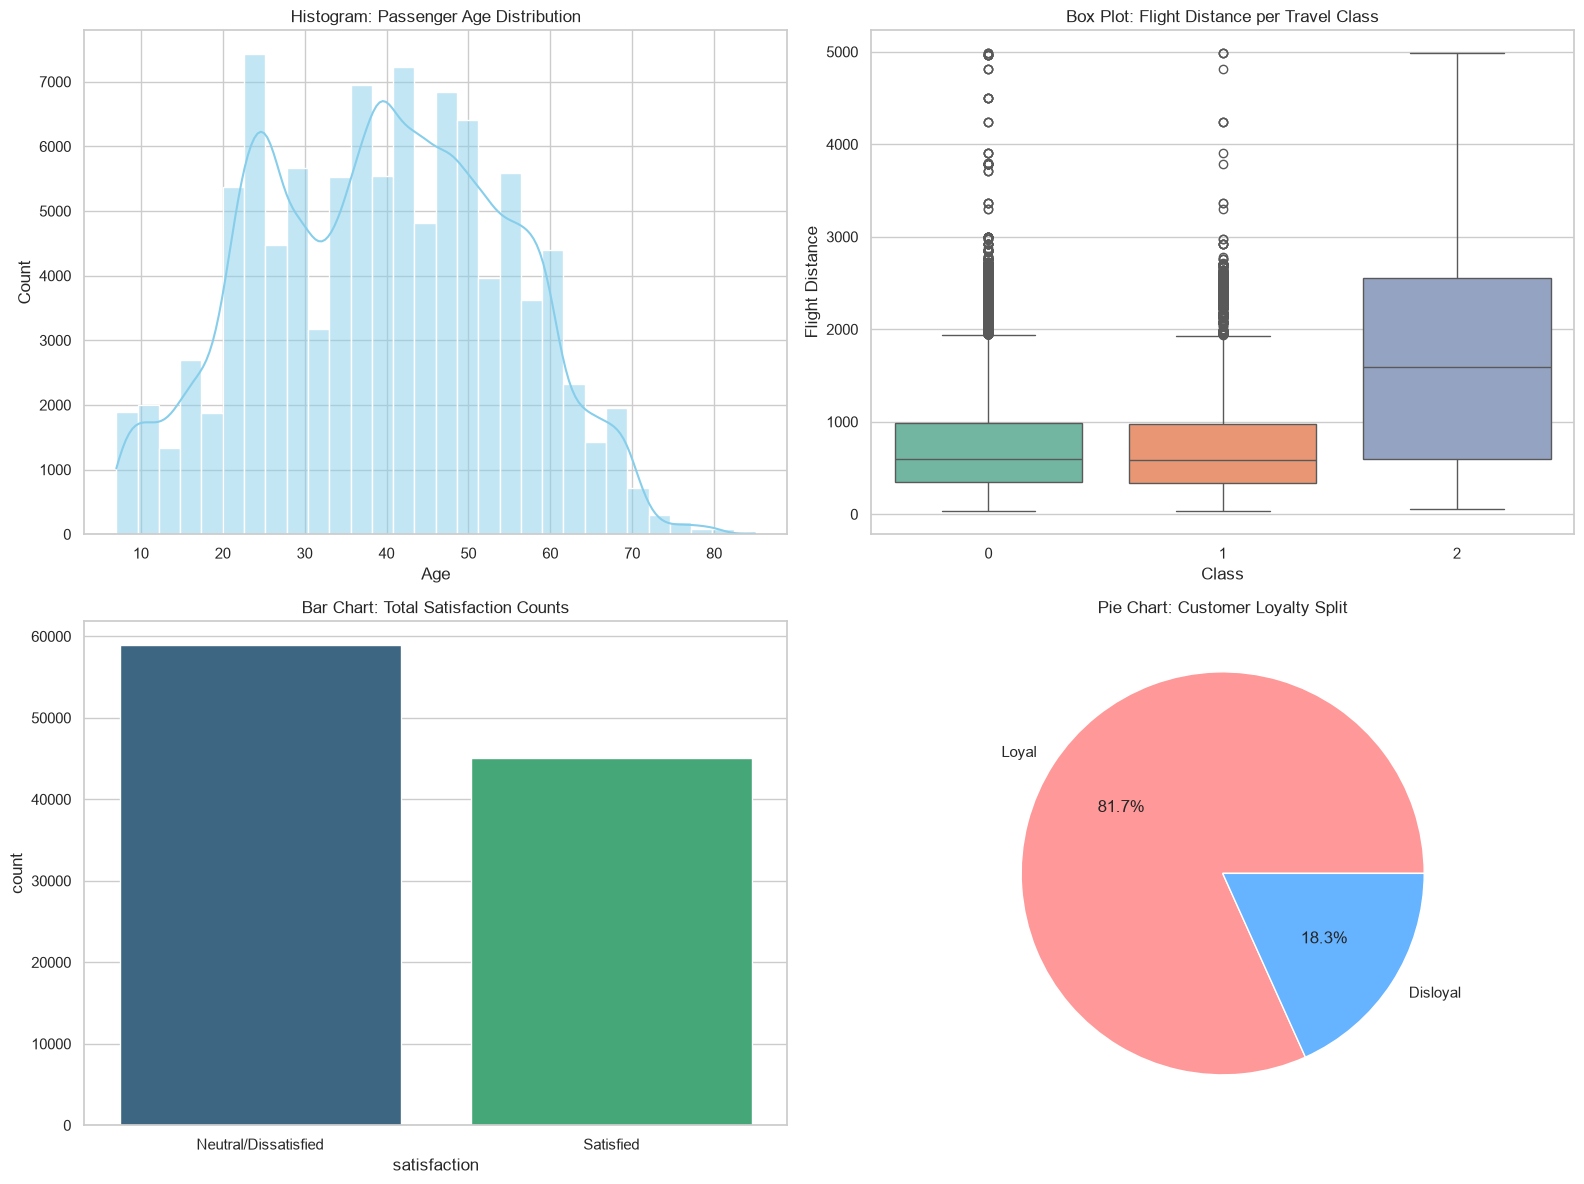

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram: Age Distribution
sns.histplot(train_df['Age'], bins=30, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Histogram: Passenger Age Distribution')

# 2. Box Plot: Flight Distance by Class (0=Eco, 1=Eco Plus, 2=Business)
sns.boxplot(x='Class', y='Flight Distance', data=train_df, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Box Plot: Flight Distance per Travel Class')

# 3. Bar Chart: Satisfaction Count
sns.countplot(x='satisfaction', data=train_df, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Bar Chart: Total Satisfaction Counts')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['Neutral/Dissatisfied', 'Satisfied'])

# 4. Pie Chart: Customer Type (0=Disloyal, 1=Loyal)
customer_counts = train_df['Customer Type'].value_counts()
axes[1, 1].pie(customer_counts, labels=['Loyal', 'Disloyal'], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
axes[1, 1].set_title('Pie Chart: Customer Loyalty Split')

plt.tight_layout()
plt.show()

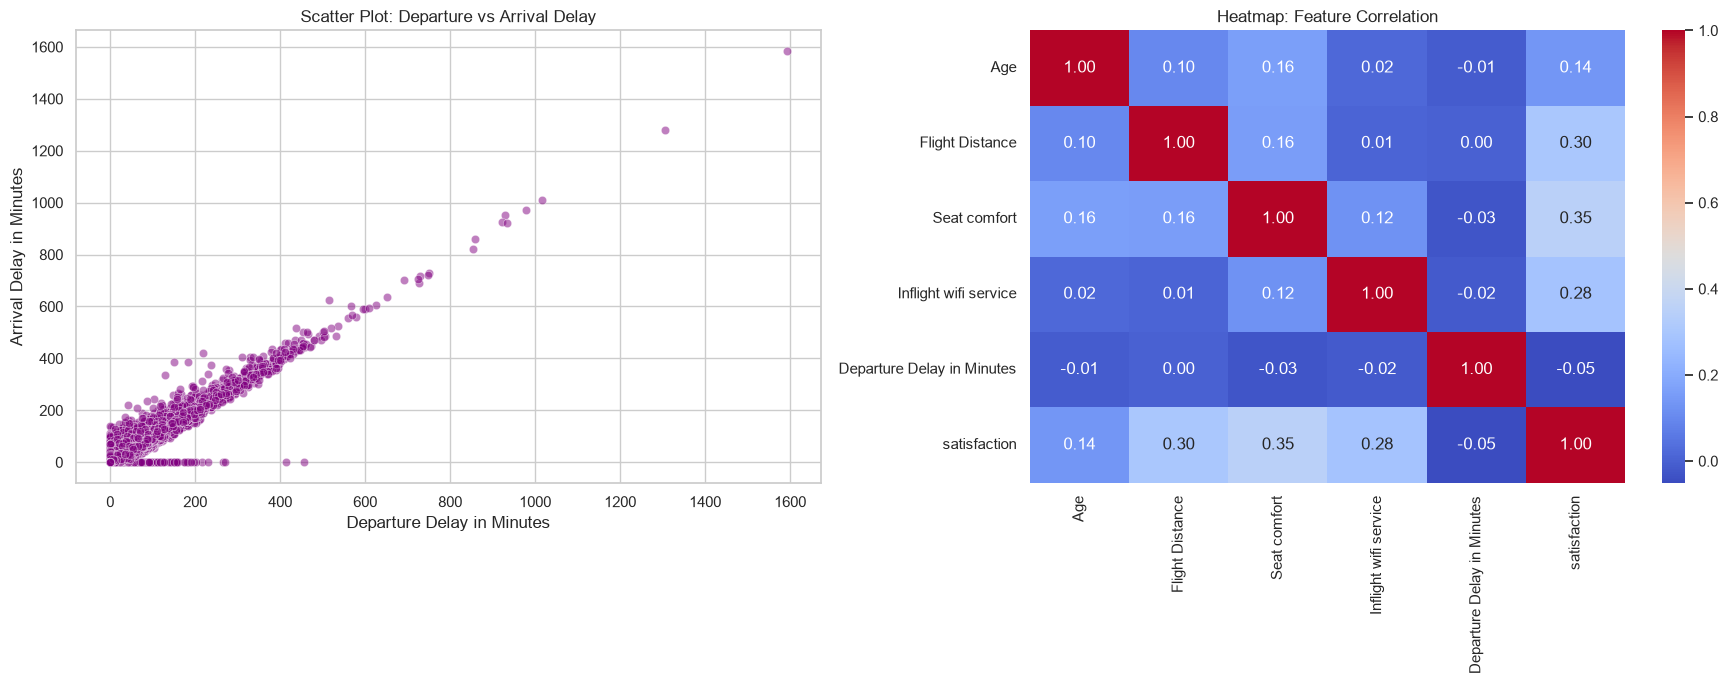

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter Plot Departure and Arrival Delay
sns.scatterplot(x='Departure Delay in Minutes', y='Arrival Delay in Minutes', data=train_df, alpha=0.5, ax=axes[0], color='purple')
axes[0].set_title('Scatter Plot: Departure vs Arrival Delay')

# Heatmap: Correlation Matrix
subset_cols = ['Age', 'Flight Distance', 'Seat comfort', 'Inflight wifi service', 'Departure Delay in Minutes', 'satisfaction']
sns.heatmap(train_df[subset_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
axes[1].set_title('Heatmap: Feature Correlation')

plt.tight_layout()
plt.show()

In [14]:
#Hypothesis Testing
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.weightstats import ztest

def format_p(p_val):
    if p_val < 0.0001:
        return "< 0.0001 (Highly Significant)"
    else:
        return f"{p_val:.4f}"



# 1. Z-TEST: Does average Age differ between Satisfied (1) and Dissatisfied (0) passengers?
satisfied_age = train_df[train_df['satisfaction'] == 1]['Age'].dropna()
dissatisfied_age = train_df[train_df['satisfaction'] == 0]['Age'].dropna()

z_stat, p_val_z = ztest(satisfied_age, dissatisfied_age)
print("1. Z-Test (Age vs Satisfaction):")
print(f"   Z-statistic = {z_stat:.2f} | P-value = {format_p(p_val_z)}")
print("   Conclusion: Passenger age significantly impacts satisfaction levels.\n")


# 2. CHI-SQUARE TEST: Is Travel Class associated with Satisfaction?
contingency_table = pd.crosstab(train_df['Class'], train_df['satisfaction'])
chi2, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("2. Chi-Square (Class vs Satisfaction):")
print(f"   Chi2 = {chi2:.2f} | P-value = {format_p(p_val_chi2)}")
print("   Conclusion: Travel class (Eco, Business) is heavily associated with satisfaction.\n")

print("   Conclusion: Flight distances are significantly different for each travel class.\n")

# 3. ANOVA: Does Flight Distance vary significantly across the 3 Travel Classes?
class_0 = train_df[train_df['Class'] == 0]['Flight Distance'].dropna()
class_1 = train_df[train_df['Class'] == 1]['Flight Distance'].dropna()
class_2 = train_df[train_df['Class'] == 2]['Flight Distance'].dropna()

f_stat, p_val_f = stats.f_oneway(class_0, class_1, class_2)
print("3. ANOVA (Flight Distance across Classes):")
print(f"   F-statistic = {f_stat:.2f} | P-value = {format_p(p_val_f)}")
print("   Conclusion: Flight distances are significantly different for each travel class.\n")

1. Z-Test (Age vs Satisfaction):
   Z-statistic = 44.64 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Passenger age significantly impacts satisfaction levels.

2. Chi-Square (Class vs Satisfaction):
   Chi2 = 26471.86 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Travel class (Eco, Business) is heavily associated with satisfaction.

   Conclusion: Flight distances are significantly different for each travel class.

3. ANOVA (Flight Distance across Classes):
   F-statistic = 14481.78 | P-value = < 0.0001 (Highly Significant)
   Conclusion: Flight distances are significantly different for each travel class.



In [15]:
# Predicting Arrival Delay based on Departure Delay
X_train_data = train_df[['Departure Delay in Minutes']]
y_train_data = train_df['Arrival Delay in Minutes']
X_test_data = test_df[['Departure Delay in Minutes']]
y_test_data = test_df['Arrival Delay in Minutes']

#Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_data, y_train_data)
y_pred_lr = lin_reg.predict(X_test_data)

print(f"Coefficient (Slope): {lin_reg.coef_[0]:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_data, y_pred_lr):.2f}")
print(f"R-squared Score (Accuracy): {r2_score(y_test_data, y_pred_lr) * 100:.2f}%")

Coefficient (Slope): 0.97
Mean Squared Error (MSE): 121.70
R-squared Score (Accuracy): 91.33%


--- Random Forest Regressor: Predicting Arrival Delay ---

Mean Squared Error (MSE): 122.31
Random Forest Score (Accuracy): 91.29%
--- Logistic Regression: Predicting Passenger Satisfaction ---

Classification Accuracy: 87.13%



c:\Users\Anshuman\Desktop\AirlinePassenger-Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<Figure size 800x600 with 0 Axes>

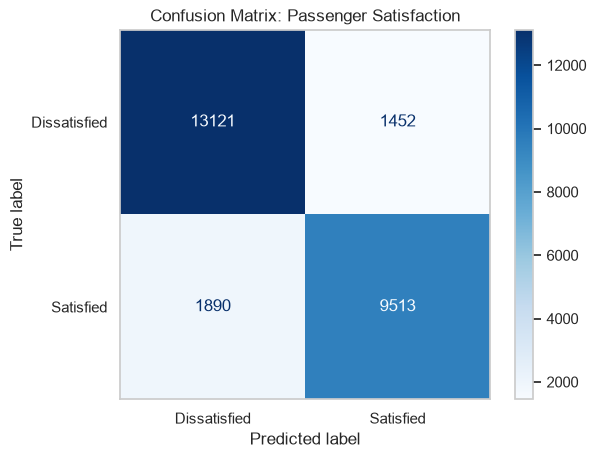

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- Random Forest Regressor: Predicting Arrival Delay ---\n")

X_train_rf = train_df[['Departure Delay in Minutes']]
y_train_rf = train_df['Arrival Delay in Minutes']
X_test_rf = test_df[['Departure Delay in Minutes']]
y_test_rf = test_df['Arrival Delay in Minutes']

# 2. Train the Random Forest Model
# n_estimators=50 builds 50 trees
rf_model = RandomForestRegressor(n_estimators=50, random_state=42)
rf_model.fit(X_train_rf, y_train_rf)

y_pred_rf = rf_model.predict(X_test_rf)

mse_rf = mean_squared_error(y_test_rf, y_pred_rf)
r2_rf = r2_score(y_test_rf, y_pred_rf)

print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Random Forest Score (Accuracy): {r2_rf * 100:.2f}%")

print("--- Logistic Regression: Predicting Passenger Satisfaction ---\n")
X_train_clf = train_df.drop(columns=['satisfaction'])
X_test_clf = test_df.drop(columns=['satisfaction'])

y_train_clf = train_df['satisfaction'].astype(int)
y_test_clf = test_df['satisfaction'].astype(int)

# Train Model
log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train_clf, y_train_clf)

# Predict & Evaluate
y_pred_clf = log_reg.predict(X_test_clf)

clf_accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"Classification Accuracy: {clf_accuracy * 100:.2f}%\n")

# Confusion Matrix
cm = confusion_matrix(y_test_clf, y_pred_clf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Dissatisfied', 'Satisfied'])

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix: Passenger Satisfaction')
plt.grid(False)
plt.show()